# DT043 – Phát hiện botnet IoT bằng autoencoder nhẹ (notebook trình bày)

**Hoàng Thanh Trà · MSSV 1150080120 · 11CNPM2**

Notebook này đi lại toàn bộ quy trình của đề tài **bằng đúng mã nguồn trong `ai/src/nbaiot`** (không viết lại thuật toán):

1. Môi trường và dataset (chứng minh đúng bộ N-BaIoT được giao)
2. Chất lượng dữ liệu và EDA
3. Chia dữ liệu chống rò rỉ
4. Huấn luyện thử V1 (AE nhẹ) cho một thiết bị, chọn ngưỡng `tr*` và cửa sổ `ws*`
5. Lượng tử hóa int8 + hiệu chỉnh ngưỡng
6. Edge benchmark rút gọn
7. Kết quả chính thức của ma trận 468 lần chạy, kiểm định, đối chiếu tiêu chí
8. MTD
9. Demo API backend

**Cách chạy:** mở bằng VS Code/Jupyter, chọn kernel `DT043/.venv` (Python 3.11), chạy lần lượt từ trên xuống.
Phần 4–6 chạy thật trên dữ liệu (≈ 1–3 phút); phần 7 đọc kết quả đã lưu trong `results/` của ma trận thí nghiệm đầy đủ (chạy lại mất ~4–5 giờ bằng `ai/scripts/04_run_matrix.py`).

In [1]:
import json, os, sys, time, importlib.util
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "ai" / "src" / "nbaiot").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "ai" / "src"))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 30, "display.width", 160)
print("Thư mục dự án:", ROOT)

Thư mục dự án: D:\BAITAP\Antoan-BM\LAB_AT_BMHTTT\DT043


## 1. Môi trường và dataset

In [2]:
env = json.loads((ROOT / "results/env_info.json").read_text(encoding="utf-8"))
pd.Series({k: env[k] for k in env if not isinstance(env[k], (dict, list))}).to_frame("giá trị")

,giá trị
os,Windows 10 (10.0.26200)
machine,AMD64
cpu,13th Gen Intel(R) Core(TM) i7-13650HX
physical_cores,14
logical_cpus,20
ram_gb,23.7
python,3.11.9
git_commit,b03872d


### 1.1 Chứng minh dùng đúng bộ N-BaIoT trong đề
Thông tin tải (nguồn, DOI, giấy phép, ngày tải, SHA-256 file zip) được ghi lúc tải bằng `ai/scripts/01_download.py`.

In [3]:
info = json.loads((ROOT / "data/DOWNLOAD_INFO.json").read_text(encoding="utf-8"))
pd.Series({k: info[k] for k in ["source_page", "url", "doi", "license", "downloaded_at_utc", "zip_bytes", "zip_sha256", "n_files"]}).to_frame("giá trị")

,giá trị
source_page,https://archive.ics.uci.edu/dataset/442/detect...
url,https://archive.ics.uci.edu/static/public/442/...
doi,10.24432/C5RC8J
license,CC BY 4.0
downloaded_at_utc,2026-10-11T04:41:52.241024+00:00
zip_bytes,1772922927
zip_sha256,64929678b081d8e579a8d7c488cf11cc588403f282d5fb...
n_files,107


Kiểm tra lại SHA-256 của cả 107 file CSV so với `data/MANIFEST.sha256` (dùng chính hàm của `ai/scripts/02_verify_manifest.py`, ≈ 1 phút):

In [4]:
spec = importlib.util.spec_from_file_location("verify_manifest", ROOT / "ai/scripts/02_verify_manifest.py")
vm = importlib.util.module_from_spec(spec); spec.loader.exec_module(vm)
t0 = time.time()
bad = vm.verify(ROOT / "data")
n_files = sum(1 for l in (ROOT / "data/MANIFEST.sha256").read_text(encoding="utf-8").splitlines() if l.strip())
print(f"{n_files} file trong manifest – sai/thiếu: {len(bad)} – {time.time() - t0:.0f} s")
print("Manifest OK – mọi file khớp SHA-256." if not bad else bad[:5])

107 file trong manifest – sai/thiếu: 0 – 7 s
Manifest OK – mọi file khớp SHA-256.


## 2. Chất lượng dữ liệu và EDA

In [5]:
fs = pd.read_csv(ROOT / "results/data_quality/file_stats.csv")
ds = pd.read_csv(ROOT / "results/data_quality/device_summary.csv")
print(f"Tổng số dòng gốc : {fs.rows_raw.sum():,}  (UCI công bố 7,062,606)")
print(f"Trùng lặp chính xác: {fs.exact_duplicates.sum():,} ({fs.exact_duplicates.sum() / fs.rows_raw.sum():.1%})")
print(f"Sau khử trùng    : {fs.rows_dedup.sum():,}")
print(f"NaN / Inf        : {fs.nan.sum()} / {fs.inf.sum()}")
print(f"Tỷ lệ tấn công : benign = {ds.rows_dedup_attack.sum() / ds.rows_dedup_benign.sum():.1f} : 1  → không dùng Accuracy")
ds

Tổng số dòng gốc : 7,062,606  (UCI công bố 7,062,606)
Trùng lặp chính xác: 157,779 (2.2%)
Sau khử trùng    : 6,904,827
NaN / Inf        : 0 / 0
Tỷ lệ tấn công : benign = 12.4 : 1  → không dùng Accuracy


,device,rows_dedup_attack,rows_dedup_benign,rows_raw_attack,rows_raw_benign,attack_to_benign_ratio
0,Danmini_Doorbell,956144,40395,968750,49548,23.67
1,Ecobee_Thermostat,810023,13111,822763,13113,61.78
2,Ennio_Doorbell,303189,35410,316400,39100,8.56
3,Philips_B120N10_Baby_Monitor,910795,165141,923437,175240,5.52
4,Provision_PT_737E_Security_Camera,752667,55169,766106,62154,13.64
5,Provision_PT_838_Security_Camera,726047,93995,738377,98514,7.72
6,Samsung_SNH_1011_N_Webcam,309809,49559,323072,52150,6.25
7,SimpleHome_XCS7_1002_WHT_Security_Camera,804263,42784,816471,46585,18.80
8,SimpleHome_XCS7_1003_WHT_Security_Camera,818390,17936,831298,19528,45.63


,device,segment,rows_raw,exact_duplicates,dup_ratio,rows_dedup
0,Danmini_Doorbell,benign,49548,9153,0.184730,40395
39,Provision_PT_737E_Security_Camera,benign,62154,6985,0.112382,55169
22,Ennio_Doorbell,benign,39100,3690,0.094373,35410
67,SimpleHome_XCS7_1002_WHT_Security_Camera,benign,46585,3801,0.081593,42784
78,SimpleHome_XCS7_1003_WHT_Security_Camera,benign,19528,1592,0.081524,17936
15,Ecobee_Thermostat,gafgyt/tcp,95021,7144,0.075183,87877


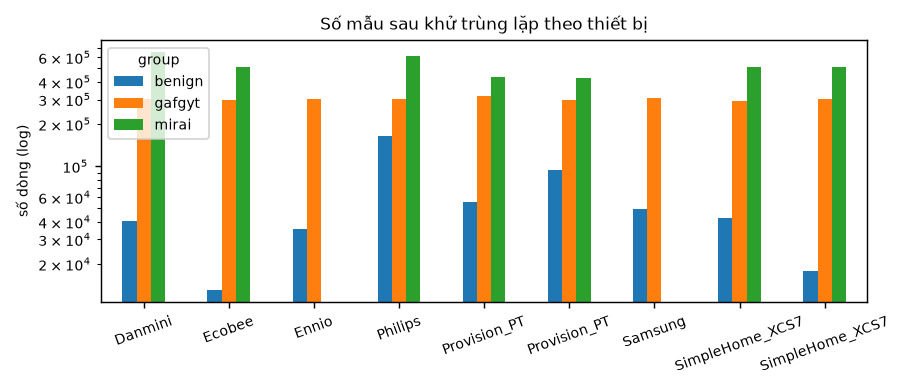

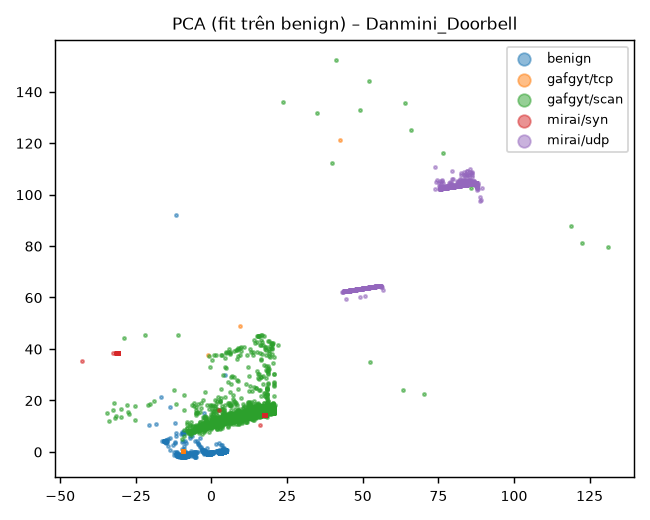

In [6]:
display(fs.sort_values("dup_ratio", ascending=False).head(6)[["device", "segment", "rows_raw", "exact_duplicates", "dup_ratio", "rows_dedup"]])
display(Image(filename=str(ROOT / "results/figures/eda_class_counts.png"), width=850))
display(Image(filename=str(ROOT / "results/figures/eda_pca_danmini.png"), width=650))

## 3. Chia dữ liệu chống rò rỉ
Benign của từng thiết bị được chia **theo thứ tự thời gian** 1/3 DStrn – 1/3 DSopt – 1/3 test, bỏ **500 dòng đệm** ở mỗi ranh giới,
scaler chỉ fit trên DStrn và loại khỏi test các dòng trùng hash với DStrn/DSopt. Cấu hình lấy từ `ai/configs/base.yaml` + `exp/E4_light.yaml` (V1).

In [7]:
from nbaiot.config import load_config
from nbaiot.split import chronological_split
from nbaiot.pipeline import load_split, make_and_train, decide, full_eval
from nbaiot.seed import set_seed

DEVICE, SEED = "Ennio_Doorbell", 42   # thiết bị có lỗi chính (flood tcp/udp); đổi tên để thử thiết bị khác
cfg = load_config("E4_light")
print("split:", cfg["split"]); print("model:", cfg["model"]); print("threshold:", cfg["threshold"])

idx = chronological_split(1000, cfg["split"]["fractions"], purge_gap=50)   # ví dụ nhỏ để thấy vùng đệm
print("Ví dụ 1000 dòng, đệm 50 → train", idx.train[[0, -1]], "opt", idx.opt[[0, -1]], "test", idx.test[[0, -1]])

split: {'method': 'chronological', 'fractions': [0.3333333, 0.3333333, 0.3333334], 'purge_gap': 500, 'drop_overlap': True, 'scaler_fit_on': 'train'}
model: {'kind': 'ae', 'hidden': [32, 8], 'activation': 'relu'}
threshold: {'rule': 'mean_std', 'max_ws': 1000}
Ví dụ 1000 dòng, đệm 50 → train [  0 332] opt [383 666] test [717 999]


In [8]:
t0 = time.time()
set_seed(SEED, cfg.get("threads"))
dd = load_split(cfg, DEVICE, SEED)
print(f"Nạp + chia + chuẩn hóa: {time.time() - t0:.1f} s")
print({k: dd.info[k] for k in ("n_benign", "n_train", "n_opt", "n_test_benign_before")})
print("Dòng trùng bị loại khỏi test:", dd.info["overlap_removed"])
pd.Series(dd.info["n_test"], name="số dòng test").to_frame().T

Nạp + chia + chuẩn hóa: 5.7 s
{'n_benign': 35410, 'n_train': 11803, 'n_opt': 11304, 'n_test_benign_before': 11303}
Dòng trùng bị loại khỏi test: {'benign': 0, 'gafgyt/combo': 0, 'gafgyt/junk': 0, 'gafgyt/scan': 0, 'gafgyt/tcp': 0, 'gafgyt/udp': 0}


,benign,gafgyt/combo,gafgyt/junk,gafgyt/scan,gafgyt/tcp,gafgyt/udp
số dòng test,11303,53014,29797,28120,93903,98355


## 4. Huấn luyện V1 (AE nhẹ 115-32-8) và chọn ngưỡng

In [9]:
from nbaiot.models import layer_dims, count_params
dims_v1, dims_b0 = layer_dims(115, cfg["model"]["hidden"]), layer_dims(115, "meidan")
print("V1:", dims_v1, f"– {count_params(dims_v1):,} tham số")
print("B0 (Meidan):", dims_b0, f"– {count_params(dims_b0):,} tham số  → V1 = {count_params(dims_v1) / count_params(dims_b0):.1%}")

t0 = time.time()
scorer, model, tinfo = make_and_train(cfg, dd.train, dd.opt, SEED)
print(f"Huấn luyện: {time.time() - t0:.1f} s, {tinfo['epochs_run']} epoch (tốt nhất: {tinfo['best_epoch']})")

V1: [115, 32, 8, 32, 115] – 8,059 tham số
B0 (Meidan): [115, 86, 58, 38, 29, 38, 58, 86, 115] – 36,876 tham số  → V1 = 21.9%


Huấn luyện: 17.5 s, 66 epoch (tốt nhất: 58)


In [10]:
opt_s = scorer(dd.opt)
test_s = {k: scorer(v) for k, v in dd.test.items()}
thr, ws, opt_fpr = decide(cfg, opt_s)
print(f"tr* = mean + std của MSE trên DSopt = {thr:.4f}  |  ws* = {ws} (FPR trên DSopt = {opt_fpr})")
res = full_eval({**cfg, "ablation_grid": False}, opt_s, test_s, thr, ws)
w = res["window"]
print(f"Mức cửa sổ – macro-F1 {w['macro_f1']:.4f} | TPR {w['tpr']:.4f} | FPR {w['fpr']:.5f} | ROC-AUC {res['roc_auc']:.4f}")
for k in ("gafgyt/tcp", "gafgyt/udp"):
    if k in test_s:
        print(f"{k}: {np.mean(test_s[k] > thr):.2%} mẫu vượt ngưỡng, MSE trung vị {np.median(test_s[k]):.3f} so với tr* {thr:.3f}")
pd.Series(w["recall_per_attack"], name="recall").round(4).to_frame()

tr* = mean + std của MSE trên DSopt = 23.3673  |  ws* = 2 (FPR trên DSopt = 0.0)
Mức cửa sổ – macro-F1 0.3204 | TPR 0.3658 | FPR 0.00000 | ROC-AUC 0.9786
gafgyt/tcp: 0.09% mẫu vượt ngưỡng, MSE trung vị 0.240 so với tr* 23.367
gafgyt/udp: 0.05% mẫu vượt ngưỡng, MSE trung vị 0.240 so với tr* 23.367


,recall
gafgyt/combo,0.9999
gafgyt/junk,0.9999
gafgyt/scan,0.9993
gafgyt/tcp,0.0001
gafgyt/udp,0.0001


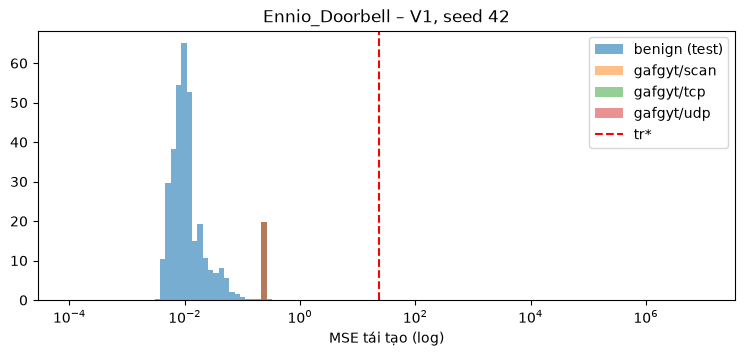

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.logspace(-4, 7, 120)
ax.hist(test_s["benign"], bins=bins, alpha=.6, label="benign (test)", density=True)
for k in ("gafgyt/scan", "gafgyt/tcp", "gafgyt/udp"):
    if k in test_s: ax.hist(test_s[k], bins=bins, alpha=.5, label=k, density=True)
ax.axvline(thr, color="r", ls="--", label="tr*")
ax.set_xscale("log"); ax.set_xlabel("MSE tái tạo (log)"); ax.legend(); ax.set_title(f"{DEVICE} – V1, seed {SEED}")
plt.show()

Nhận xét: với Ennio, gafgyt combo/junk/scan nằm hẳn trên ngưỡng, còn **gafgyt/tcp và gafgyt/udp** (flood giả mạo nguồn) gần như toàn bộ nằm dưới ngưỡng nên recall ≈ 0 – đây là lỗi chính được phân tích trong báo cáo (Ennio không có dữ liệu Mirai).
Đây là kết quả **1 thiết bị × 1 seed**; ở thiết bị khác (ví dụ Danmini) tcp/udp lại được bắt, nên kết luận phải dựa trên trung bình 9 thiết bị × 5 seed ở phần 7.

## 5. Lượng tử hóa int8 + hiệu chỉnh ngưỡng

In [12]:
from nbaiot.quantize import to_tflite, TFLiteRunner
from nbaiot.metrics import evaluate_segments

blob32 = to_tflite(model, "fp32")
blob8 = to_tflite(model, "int8", rep_data=dd.train, seed=SEED)
r8 = TFLiteRunner(blob8, num_threads=1)
test8 = {k: r8.mse(v) for k, v in dd.test.items()}
keep = evaluate_segments(test8, thr, ws)
thr8, ws8, _ = decide(cfg, r8.mse(dd.opt))
recal = evaluate_segments(test8, thr8, ws8)
pd.DataFrame({
    "fp32": {"KB": len(blob32) / 1024, "tr*": thr, "ws*": ws, "macro_f1": w["macro_f1"], "TPR": w["tpr"], "FPR": w["fpr"]},
    "int8 giữ ngưỡng fp32": {"KB": len(blob8) / 1024, "tr*": thr, "ws*": ws, "macro_f1": keep["macro_f1"], "TPR": keep["tpr"], "FPR": keep["fpr"]},
    "int8 hiệu chỉnh trên DSopt": {"KB": len(blob8) / 1024, "tr*": thr8, "ws*": ws8, "macro_f1": recal["macro_f1"], "TPR": recal["tpr"], "FPR": recal["fpr"]},
}).T.round(5)

INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\sm_twhtj38h\sm\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\sm_twhtj38h\sm\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\sm_d5_2dt6j\sm\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\sm_d5_2dt6j\sm\assets


D:\BAITAP\Antoan-BM\LAB_AT_BMHTTT\DT043\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,KB,tr*,ws*,macro_f1,TPR,FPR
fp32,33.66406,23.36726,2.0,0.32045,0.36584,0.0
int8 giữ ngưỡng fp32,15.32031,23.36726,2.0,0.32045,0.36584,0.0
int8 hiệu chỉnh trên DSopt,15.32031,22.74350,2.0,0.32045,0.36584,0.0


### 5.1 Đối chiếu với lần chạy chính thức và gói đã triển khai (cùng seed 42)
Nếu quy trình tái lập được, ngưỡng/cửa sổ và metric chạy lại trong notebook phải trùng (hoặc rất sát) với `results/raw/E4_light/<thiết bị>/seed=42/metrics.json`
và `artifacts/deploy/<thiết bị>/meta.json` (gói backend đang dùng).

In [13]:
off_run = json.loads((ROOT / f"results/raw/E4_light/{DEVICE}/seed=42/metrics.json").read_text(encoding="utf-8"))["result"]
meta = json.loads((ROOT / f"artifacts/deploy/{DEVICE}/meta.json").read_text(encoding="utf-8"))
pd.DataFrame({
    "notebook (chạy lại)": {"tr* fp32": thr, "ws* fp32": ws, "macro_f1 fp32": w["macro_f1"], "TPR fp32": w["tpr"], "FPR fp32": w["fpr"],
                             "tr* int8": thr8, "ws* int8": ws8, "KB int8": len(blob8) / 1024},
    "lần chạy chính thức": {"tr* fp32": off_run["thr"], "ws* fp32": off_run["ws"], "macro_f1 fp32": off_run["window"]["macro_f1"],
                            "TPR fp32": off_run["window"]["tpr"], "FPR fp32": off_run["window"]["fpr"]},
    "gói triển khai": {"tr* int8": meta["threshold"], "ws* int8": meta["window_size"], "KB int8": meta["size_bytes"] / 1024},
}).round(4)

,notebook (chạy lại),lần chạy chính thức,gói triển khai
tr* fp32,23.3673,23.3673,NaN
ws* fp32,2.0000,2.0000,NaN
macro_f1 fp32,0.3204,0.3204,NaN
TPR fp32,0.3658,0.3658,NaN
FPR fp32,0.0000,0.0000,NaN
tr* int8,22.7435,NaN,22.7435
ws* int8,2.0000,NaN,2.0000
KB int8,15.3203,NaN,15.3203


## 6. Edge benchmark rút gọn
Bản đầy đủ (`ai/scripts/05_bench_edge.py`) ghim 1 luồng vào một lõi E-core, 10.000 lần × 5 lượt trong process riêng.
Ở đây chạy rút gọn 3.000 lần × 3 lượt, batch 1, 1 luồng, không ghim lõi, nên số đo chỉ để minh họa. Energy proxy (CPU-time × 55 W / 14 lõi) cần nhiều lần gọi vì đồng hồ CPU của Windows chỉ chính xác ~15,6 ms, nên chỉ lấy từ bảng chính thức bên dưới.

In [14]:
from nbaiot.bench import bench_tflite
x = dd.test["benign"][:5000].astype(np.float32)
rows = {}
for name, blob in (("V1 fp32", blob32), ("V1 int8", blob8)):
    b = bench_tflite(blob, x, threads=1, batch=1, n_iter=3000, warmup=200, repeats=3)
    rows[name] = {"KB": len(blob) / 1024, "p50_us": b["p50_us"], "p95_us": b["p95_us"], "mẫu/s": b["throughput_samples_s"],
                  "RAM tăng (MB)": b["rss_delta_mb"]}
pd.DataFrame(rows).T.round(2)

D:\BAITAP\Antoan-BM\LAB_AT_BMHTTT\DT043\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,KB,p50_us,p95_us,mẫu/s,RAM tăng (MB)
V1 fp32,33.66,2.7,4.80,330505.67,0.07
V1 int8,15.32,2.3,4.27,388222.20,0.27


In [15]:
deck = json.loads((ROOT / "report/deck_data.json").read_text(encoding="utf-8"))
off = pd.DataFrame(deck["edge"]).T[["size_kb", "p50_us", "p95_us", "throughput_samples_s", "rss_delta_mb", "energy_proxy_uJ"]]
display(Markdown("**Kết quả chính thức** (ghim E-core, P1 = 1 luồng batch 1; P0 = 20 luồng):"))
off.loc[[i for i in off.index if i.startswith("V1") or i.startswith("B0_fp32")]].astype(float).round(2)

**Kết quả chính thức** (ghim E-core, P1 = 1 luồng batch 1; P0 = 20 luồng):

,size_kb,p50_us,p95_us,throughput_samples_s,rss_delta_mb,energy_proxy_uJ
B0_fp32_P1_edge,147.75,16.94,21.98,40119.68,3.08,83.48
B0_fp32_P0_b1,147.75,1450.37,2162.80,690.68,3.66,11117.86
B0_fp32_P0_b256,147.75,2400.54,3162.29,105824.21,4.63,80.57
V1_fp32_P1_edge,33.66,10.56,12.70,63626.73,3.23,44.20
V1_fp32_P0_b1,33.66,495.89,1000.67,1965.26,3.61,4061.16
V1_fp32_P0_b256,33.66,1397.57,2036.64,183091.97,4.52,43.16
V1_int8_P1_edge,15.32,8.98,10.76,102898.87,4.64,40.51
V1_int8_P0_b1,15.32,473.27,961.09,2049.19,6.54,3937.17
V1_int8_P0_b256,15.32,1150.19,1686.47,223011.09,5.98,30.98


## 7. Kết quả chính thức của ma trận thí nghiệm (468 lần chạy)

In [16]:
s = pd.read_csv(ROOT / "results/tables/summary_by_config.csv")
s[["config", "n_seeds", "n_runs", "params", "macro_f1_mean", "macro_f1_ci95", "tpr_mean", "fpr_mean", "f1_balanced_mean"]].round(4)

,config,n_seeds,n_runs,params,macro_f1_mean,macro_f1_ci95,tpr_mean,fpr_mean,f1_balanced_mean
0,B0 (Meidan AE),5,45,36876.0,0.7061,0.0658,0.8222,0.0025,0.8841
1,B1 global,5,45,36876.0,0.6843,0.3578,0.8094,0.0000,0.8782
2,B1 chung+pdnorm,5,45,36876.0,0.7748,0.0391,0.8632,0.0022,0.9098
3,B2 IsolationForest,5,45,NaN,0.8857,0.0144,0.9282,0.0025,0.9550
4,V1 AE nhẹ,5,45,8059.0,0.6890,0.0560,0.8115,0.0027,0.8779
5,V2 cửa sổ L001,3,27,699.0,0.8405,0.0516,0.9164,0.0036,0.9470
6,V2 cửa sổ L01,3,27,699.0,0.6846,0.2150,0.7998,0.0017,0.8701
7,V2 cửa sổ L1,3,27,699.0,0.6806,0.0791,0.8076,0.0012,0.8787
8,V2 cửa sổ L3,3,27,699.0,0.6651,0.1609,0.8094,0.0011,0.8832
9,V2 cửa sổ L5,3,27,699.0,0.6520,0.1658,0.7758,0.0006,0.8561


mean                    std        
group            8_loai_con_lai tcp_udp 8_loai_con_lai tcp_udp
exp                                                           
E1_baseline              0.9999  0.4667         0.0004  0.5017
E2_global                1.0000  0.4000         0.0000  0.4926
E2_shared_pdnorm         0.9999  0.6000         0.0008  0.4926
E3_iforest               0.9728  0.7778         0.1399  0.4181
E4_light                 0.9999  0.4222         0.0004  0.4967
E4_tiny_L001             0.9997  0.7037         0.0012  0.4609
E4_tiny_L01              0.9999  0.4074         0.0003  0.4960
E4_tiny_L1               0.9925  0.3704         0.0388  0.4874
E4_tiny_L3               0.9761  0.3333         0.0930  0.4758
E4_tiny_L5               0.9698  0.3333         0.1111  0.4758
E6_leak                  0.9998  0.4074         0.0023  0.4960
E9_poison_1              0.9885  0.0000         0.0406  0.0000
E9_poison_5              0.8648  0.0000         0.2488  0.0000
E9_robust                0.9999  0.4445         0.0004  0.5016

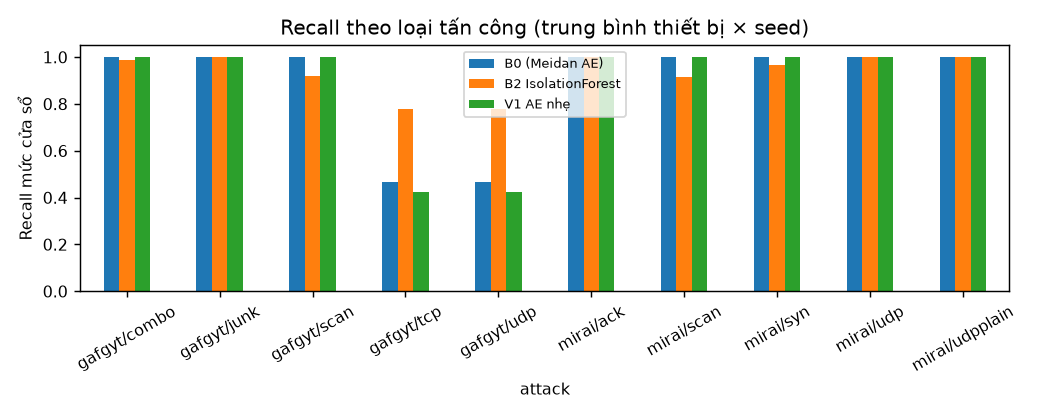

In [17]:
display(pd.read_csv(ROOT / "results/tables/recall_groups.csv", header=[0, 1], index_col=0).round(4))
display(Image(filename=str(ROOT / "results/figures/fig_recall_per_attack.png"), width=850))

In [18]:
st = pd.read_csv(ROOT / "results/tables/stat_tests.csv")
st[["test", "metric", "n", "mean_diff", "wins", "p", "p_holm"]].round(4)

,test,metric,n,mean_diff,wins,p,p_holm
0,RQ2: per-device > global,macro_f1,9,0.0218,4,0.2852,1.0000
1,RQ2: per-device > global,fpr,9,0.0025,4,0.0625,0.9375
2,RQ2b: model riêng > model chung (cùng pdnorm),macro_f1,9,-0.0686,2,0.9766,1.0000
3,RQ2b: model riêng > model chung (cùng pdnorm),fpr,9,0.0003,3,0.3750,1.0000
4,RQ2c: pdnorm > global norm (cùng model chung),macro_f1,9,0.0904,6,0.1504,1.0000
5,RQ2c: pdnorm > global norm (cùng model chung),fpr,9,0.0022,5,0.0312,0.5000
6,RQ3: V1 vs B0,macro_f1,9,-0.0171,1,0.1289,1.0000
7,RQ3: V1 vs B0,fpr,9,0.0002,3,0.6250,1.0000
8,B0 > IsolationForest,macro_f1,9,-0.1796,4,0.8496,1.0000
9,B0 > IsolationForest,fpr,9,-0.0000,3,0.6094,1.0000


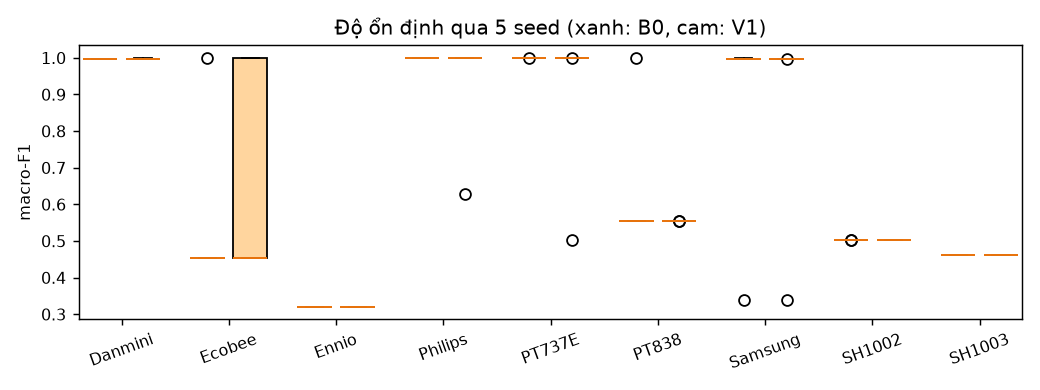

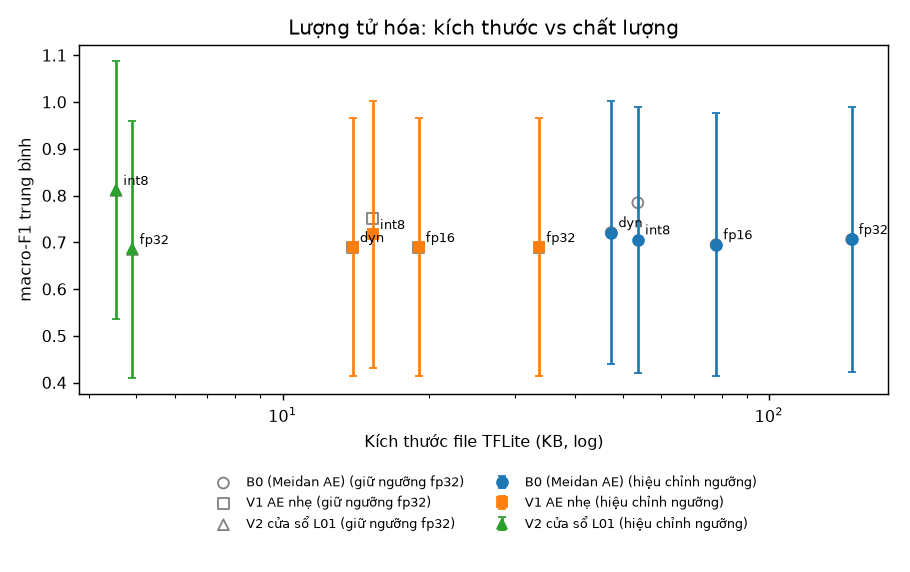

In [19]:
display(Image(filename=str(ROOT / "results/figures/fig_seed_stability.png"), width=800))
display(Image(filename=str(ROOT / "results/figures/fig_quantization_tradeoff.png"), width=800))

### Đối chiếu tiêu chí đã chốt trước (không chỉnh sau khi có kết quả)

In [20]:
pd.read_csv(ROOT / "results/tables/criteria_check.csv")

,RQ,criterion,value,pass
0,RQ1,TPR ≥ 0.99 và FPR ≤ 0.02 (B0),"TPR=0.8222, FPR=0.0025",False
1,RQ2,B0 > B1 ở ≥7/9 thiết bị và p < 0.05,"thắng 4/9, p=0.2852",False
2,RQ3,V1 ≤ 25% tham số và Δmacro-F1 ≤ 0.01,"tham số 21.9%, Δ=+0.0171",False
3,RQ4,int8+recal: Δmacro-F1 ≤ 0.005 và kích thước ≤ ...,"Δ=-0.0278, kích thước 45.5%",False
4,RQ5,"P1: p95 ≤ 1 ms, model ≤ 50 KB, RSS tăng ≤ 50 M...","p95=10.8 µs, 15.3 KB, ΔRSS=4.6 MB",True


## 8. Moving Target Defence (mô phỏng HARM rút gọn)

,period,policy,asp_mean,asp_std,attack_cost_mean_mean,attack_cost_mean_std,time_to_compromise_mean_mean,time_to_compromise_mean_std,mtd_moves_per_run_mean,mtd_moves_per_run_std
0,5,combined,0.0000,0.0000,35.7246,0.1076,NaN,NaN,8.0000,0.0000
1,5,diversity,0.2030,0.0117,28.4928,0.0899,18.0462,0.0602,3.8139,0.0140
2,5,none,0.4985,0.0142,29.3870,0.1455,17.4365,0.0500,0.0000,0.0000
3,5,shuffle,0.0000,0.0000,34.8034,0.0838,NaN,NaN,4.0000,0.0000
4,10,combined,0.0000,0.0000,29.6594,0.1941,NaN,NaN,4.0000,0.0000
5,10,diversity,0.3582,0.0062,29.0193,0.1359,17.4096,0.0727,1.6679,0.0076
6,10,none,0.4985,0.0142,29.3870,0.1455,17.4365,0.0500,0.0000,0.0000
7,10,shuffle,0.0000,0.0000,29.2500,0.1558,NaN,NaN,2.0000,0.0000
8,20,combined,0.3273,0.0152,27.3992,0.0680,17.2241,0.0526,1.6727,0.0152
9,20,diversity,0.4369,0.0126,29.3870,0.1455,17.0750,0.0577,0.5905,0.0132


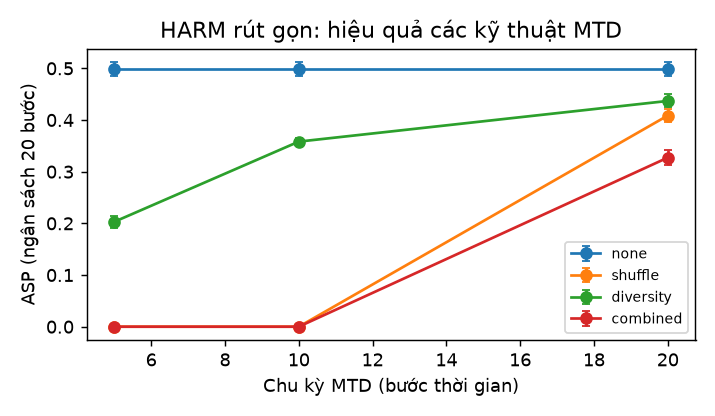

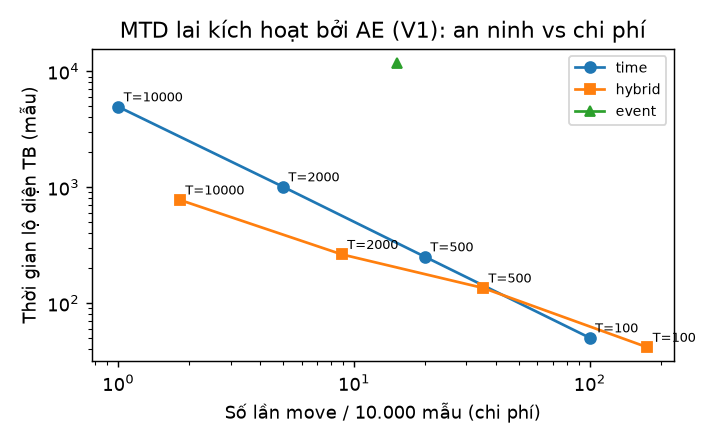

In [21]:
display(pd.read_csv(ROOT / "results/tables/mtd_harm_policies.csv").round(4))
display(Image(filename=str(ROOT / "results/figures/fig_mtd_harm.png"), width=700))
display(Image(filename=str(ROOT / "results/figures/fig_mtd_hybrid_tradeoff.png"), width=700))

## 9. Demo API backend (FastAPI + SQLite + gói triển khai V1 int8)
Dùng CSDL tạm để không ghi vào `db/dt043.sqlite3`. Dashboard đầy đủ: `.venv\Scripts\python -m uvicorn backend.app.main:app --port 8000` rồi mở http://127.0.0.1:8000/.

In [22]:
import tempfile
os.environ["DT043_DB"] = str(Path(tempfile.mkdtemp()) / "nb_demo.sqlite3")
sys.path.insert(0, str(ROOT))
from fastapi.testclient import TestClient
from backend.app.main import app

with TestClient(app) as c:
    print(c.get("/api/health").json())
    rows = []
    for dev, seg in [("Danmini_Doorbell", "mirai/syn"), ("Ennio_Doorbell", "benign"), ("Ennio_Doorbell", "gafgyt/tcp")]:
        r = c.post(f"/api/replay/{dev}?segment={seg}&n=2000&offset=0").json()
        rows.append({"thiết bị": dev, "segment": seg, "mẫu": r["n_samples"], "vượt ngưỡng": r["n_flagged"],
                     "cửa sổ cảnh báo": f"{r['n_alarm_windows']}/{r['n_windows']}", "µs/mẫu": round(r["infer_us_per_sample"], 2),
                     "cảnh báo": r["alert_id"] is not None})
    display(pd.DataFrame(rows))
    display(pd.DataFrame(c.get("/api/mtd/actions").json()))

D:\BAITAP\Antoan-BM\LAB_AT_BMHTTT\DT043\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


D:\BAITAP\Antoan-BM\LAB_AT_BMHTTT\DT043\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{'status': 'ok', 'models_loaded': 9, 'bundle_errors': {}}


,thiết bị,segment,mẫu,vượt ngưỡng,cửa sổ cảnh báo,µs/mẫu,cảnh báo
0,Danmini_Doorbell,mirai/syn,2000,2000,1989/1989,0.64,True
1,Ennio_Doorbell,benign,2000,0,0/1999,0.57,False
2,Ennio_Doorbell,gafgyt/tcp,2000,2,0/1999,0.48,False


,id,device_id,alert_id,technique,trigger_kind,detail,created_at,device
0,2,1,1,diversity,event,firmware fw-A -> fw-C,2026-10-20 05:30:22,Danmini_Doorbell
1,1,1,1,shuffle,event,IP 10.0.0.218 -> 10.0.0.100,2026-10-20 05:30:22,Danmini_Doorbell


## 10. Kết luận
- AE per-device bắt gần tuyệt đối 8/10 loại tấn công với FPR rất thấp (B0 0,0025); bỏ sót flood tcp/udp giả mạo nguồn của BASHLITE.
- V1 int8 ≈ 15 KB, vài µs/mẫu trên 1 lõi → khả thi cho edge (RQ5 đạt); RQ1–RQ4 không đạt và được giữ nguyên tiêu chí.
- Kết quả dao động theo seed → cần nhiều lần chạy và kiểm định; MTD kết hợp shuffle + diversity cho ASP thấp nhất, MTD lai dùng cảnh báo AE giảm thời gian lộ diện.